In [3]:
!pip install pandas numpy matplotlib seaborn scikit-learn

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [5]:
pd.set_option("display.float_format", lambda x: f"{x:.2f}")


In [6]:
with open("house_rent_price.csv", "rb") as f:
    print(f.read(100))

b'PK\x03\x04\n\x00\x00\x00\x00\x00\x87N\xe2@\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\t\x00\x00\x00docProps/PK\x03\x04\x14\x00\x00\x00\x08\x00\x87N\xe2@H\x81\x0f\x80/\x01\x00\x007\x02\x00\x00\x10\x00\x00\x00docProps/app.xml\x9d\x91\xc1J\x031\x14E\xf7\x82\xff\x10\xb2o3'


In [7]:
import pandas as pd

df = pd.read_excel("house_rent_price.csv")
df.head()

,Area_sqft,Bedrooms,House_Age,Distance-km,Parking,Price_INR,City
0,723,3,13,3.60,1.00,8000,Ahmedabad
1,2435,5,6,1.30,2.00,30000,Ahmedabad
2,2137,5,7,7.00,1.00,25000,Ahmedabad
3,1598,4,36,12.00,1.00,12000,Ahmedabad
4,1583,3,29,10.50,0.00,10000,Ahmedabad


In [8]:
df.shape


(10, 7)

In [9]:
df.head()

,Area_sqft,Bedrooms,House_Age,Distance-km,Parking,Price_INR,City
0,723,3,13,3.60,1.00,8000,Ahmedabad
1,2435,5,6,1.30,2.00,30000,Ahmedabad
2,2137,5,7,7.00,1.00,25000,Ahmedabad
3,1598,4,36,12.00,1.00,12000,Ahmedabad
4,1583,3,29,10.50,0.00,10000,Ahmedabad


In [10]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Area_sqft    10 non-null     int64  
 1   Bedrooms     10 non-null     int64  
 2   House_Age    10 non-null     int64  
 3   Distance-km  10 non-null     float64
 4   Parking      9 non-null      float64
 5   Price_INR    10 non-null     int64  
 6   City         10 non-null     str    
dtypes: float64(2), int64(4), str(1)
memory usage: 791.0 bytes


In [11]:
df.isnull().sum()

Area_sqft      0
Bedrooms       0
House_Age      0
Distance-km    0
Parking        1
Price_INR      0
City           0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df.shape

(10, 7)

,Area_sqft,Bedrooms,House_Age,Distance-km,Parking,Price_INR
count,10.00,10.00,10.00,10.00,9.00,10.00
mean,1584.90,3.70,19.80,10.38,0.78,13350.00
std,752.85,1.06,12.97,5.55,0.67,8158.33
min,723.00,2.00,6.00,1.30,0.00,6000.00
25%,808.75,3.00,7.00,7.75,0.00,7250.00
50%,1590.50,3.50,21.00,10.30,1.00,11000.00
75%,2217.25,4.75,30.50,13.27,1.00,14750.00
max,2647.00,5.00,36.00,20.40,2.00,30000.00


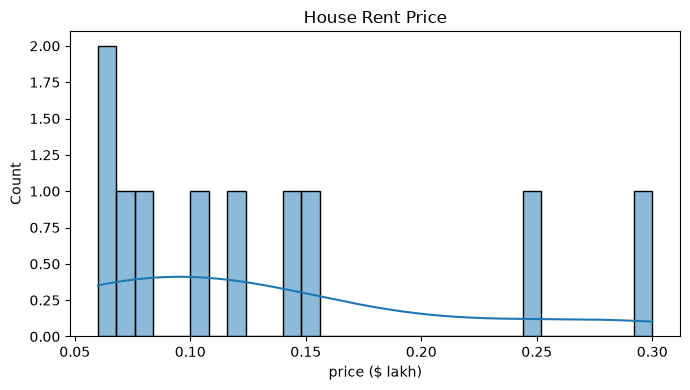

In [14]:
display(df.describe().round(2))

plt.figure(figsize=(7,4))
sns.histplot(df["Price_INR"] / 100000, bins=30, kde=True)
plt.title("House Rent Price")
plt.xlabel("price ($ lakh)")
plt.tight_layout()
plt.show()


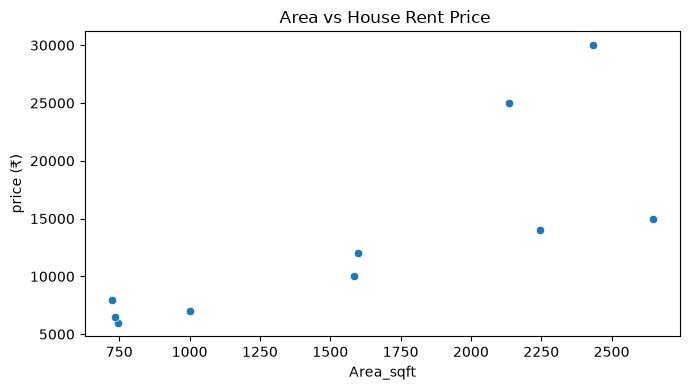

In [15]:
plt.figure(figsize=(7,4))
sns.scatterplot(data=df, x="Area_sqft", y="Price_INR")
plt.title(" Area vs House Rent Price")
plt.ylabel("price (₹)")
plt.tight_layout()
plt.show()

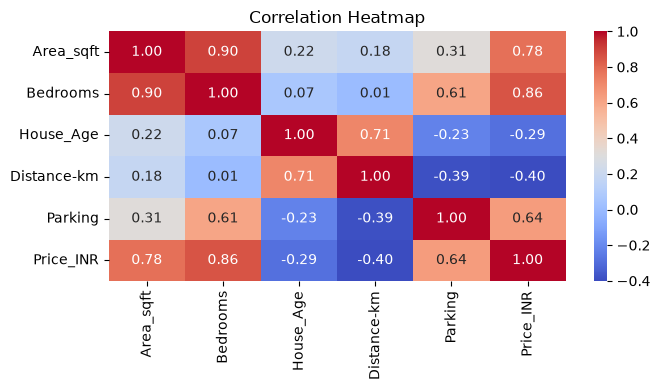

In [16]:
plt.figure(figsize=(7,4))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")   
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [17]:
x = df.drop(columns=["Price_INR"])
y = df["Price_INR"]

In [18]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [19]:
print("Training rows:", x_train.shape[0])
print("Testing rows:", x_test.shape[0])

Training rows: 8
Testing rows: 2


In [20]:
print("--- Features Data Types ---")
print(x_train.dtypes)

print("\n--- Missing Values ---")
print(x_train.isnull().sum())

print("\n--- Target Variable Head ---")
print(y_train.head())

--- Features Data Types ---
Area_sqft        int64
Bedrooms         int64
House_Age        int64
Distance-km    float64
Parking        float64
City               str
dtype: object

--- Missing Values ---
Area_sqft      0
Bedrooms       0
House_Age      0
Distance-km    0
Parking        1
City           0
dtype: int64

--- Target Variable Head ---
5    15000
0     8000
7    14000
2    25000
9     6500
Name: Price_INR, dtype: int64


In [21]:
# 1. Fill the missing value in the Parking column (or your whole dataframe)
df['Parking'] = df['Parking'].fillna(df['Parking'].median())

# 2. Re-define your features and target variables
X = df[['Area_sqft', 'Bedrooms', 'House_Age', 'Distance-km', 'Parking']]
y = df['Price_INR']

# 3. Re-split your dataset (so x_train gets the updated, clean data)
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [22]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(x_train, y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[ 1.13, 6889.59, -127.69, -461.72,-4347.72]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['Area_sqft','Bedrooms','House_Age','Distance-km','Parking']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-4381
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)


In [23]:
y_pred = model.predict(x_test)

In [24]:
print(y_pred)


[ 1709.77797137 22746.00586219]


In [25]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE: ₹{mae:,.0f}")
print(f"RMSE: ₹{rmse:,.0f}")
print(f"R² Score: {r2:.3f}")

MAE: ₹6,272
RMSE: ₹6,348
R² Score: 0.695


In [28]:
new_house = pd.DataFrame([{
    "Area_sqft": 1500,
    "Bedrooms": 3,
    "House_Age": 8,
    "Distance-km": 5.0,  # Changed underscore (_) to a hyphen (-)
    "Parking": 1
}])

# Changed (0) to [0] at the end
predicted_price = model.predict(new_house)[0] 
print(f"Estimated house price: ₹{predicted_price:,.0f}")


Estimated house price: ₹10,299
